# 1. Open FlowMapper.org project files in Python

Every dataset folder in the FlowMapper repository has a `flowmapper_*.json` project, saved on
FlowMapper.org with **File > Project > Save Project**, and a `flowmapper_*.png` picture of that map.
This notebook

1. loads every project file with `fm.Project.load`,
2. draws it exactly as saved (`contrast=False`) next to the web site's picture,
3. checks that a project saved by Python reads back unchanged,
4. restyles one project for stronger figure-ground contrast.

### Setup

Imports, the data folder, and a few helpers used below: `figure_ground()` (the high-contrast look),
`size_nodes_by_total_flow()`, `show()` / `map_image()` / `show_grid()` (draw maps) and
`compare_settings()` (draw the same map with different settings side by side).

In [1]:
%matplotlib inline
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowmapper_org as fm

# Example data of the FlowMapper GitHub repository (folder "Data"): FLOWMAPPER_DATA, else the
# repository these notebooks live in (python/notebooks -> ../../Data), else a local clone.
_candidates = [os.environ.get("FLOWMAPPER_DATA"), Path.cwd().parent.parent / "Data", r"D:\GitHub\flowmapper\Data"]
DATA = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
assert DATA is not None, ("FlowMapper example data not found: clone https://github.com/geo-social/flowmapper "
                          "and set FLOWMAPPER_DATA to its Data folder")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("flowmapper.org", fm.__version__, "- mirrors FlowMapper.org", fm.FLOWMAPPER_WEB_VERSION)

# ---------------------------------------------------------------------------------------------
# The look used in these notebooks: figure-ground contrast.
#   * flows are the figure: Tapered Fading Arc (TAF), dark colour ramps, full opacity;
#   * regions are the ground: their colours are kept but drawn pale (35 % opacity);
#   * nodes are drawn on top of the flows, dark grey with a white outline.
# figure_ground() only sets ordinary FlowMapper settings, so the projects still open on
# FlowMapper.org. CONTRAST holds two Python-only drawing options (never saved in the file):
#   flow_contrast - raises the opacity of the fading arcs, so small flows stay visible;
#   flow_halo     - a thin white casing that separates flows from the regions below.
# ---------------------------------------------------------------------------------------------
CONTRAST = dict(flow_contrast=0.5, flow_halo=("#ffffff", 0.7))

# Zoom extents (west, south, east, north), a drawing option: render(..., extent=...).
# The legend and title are kept outside the extent.
LOWER48 = (-125, 24, -66.5, 49.5)
EUROPE = (-12, 34, 58, 68)


def us_extent(p):
    """LOWER48 when most of the project's nodes are in the contiguous U.S., else None.

    Every U.S. map in these notebooks is zoomed to the lower 48 (not Alaska and Hawaii):
    map_image() / show() use this whenever no extent is given."""
    ns = p.node_settings
    xf, yf = ns.get("X"), ns.get("Y")
    if p.nodes is None or xf not in p.nodes.columns or yf not in p.nodes.columns:
        return None
    x = pd.to_numeric(p.nodes[xf], errors="coerce")
    y = pd.to_numeric(p.nodes[yf], errors="coerce")
    ok = x.notna() & y.notna()
    if not ok.any():
        return None
    w, s, e, n = LOWER48
    inside = (x[ok].between(w, e) & y[ok].between(s, n)).mean()
    return LOWER48 if inside >= 0.8 else None

# Dark ramps (light end, dark end). The light end is a mid-tone, so the smallest flows
# are still clearly visible; a ColorBrewer ramp such as "Blues" starts almost white.
FLOW_RAMPS = {
    "navy":   ("#4a6fa5", "#0b1f4b"),
    "orange": ("#f16913", "#7f2704"),
    "purple": ("#807dba", "#3f007d"),
    "teal":   ("#3a9e8f", "#00332b"),
}


def figure_ground(p, flows="navy", region_opacity=35, node_color="#3d3d3d"):
    """Pale regions, dark prominent flows, nodes on top (ordinary FlowMapper settings)."""
    lo, hi = FLOW_RAMPS[flows] if flows in FLOW_RAMPS else flows
    p.flow_settings.update(flowStyleName="TAF", clrScheme="Custom", minCustomColor=lo, maxCustomColor=hi,
                           fillOpacity=100)
    p.region_settings.update(fillOpacity=region_opacity, strokeColor="#9e9e9e", strokeWidth=0.4)
    p.node_settings.update(clrScheme="Custom", minCustomColor=node_color, maxCustomColor=node_color,
                           noAttrFillColor=node_color, strokeColor="#ffffff", strokeWidth=0.8, fillOpacity=100)
    p.view_settings["drawingOrder"] = "nodes"          # nodes on top of flows
    return p


def size_nodes_by_total_flow(p, rmin=2, rmax=16, title="Total flow (in + out)", measure="__fm:grossflow"):
    """Circle size = gross flow (in-flow + out-flow), calculated from the flows.

    measure="__fm:inflow" sizes by flow received instead: better when one origin sends
    everything (refugees from one country), where the origin's total would dwarf the rest."""
    p.node_settings.update(ifMapAttribute=True, volume=measure, cfMethod="Proportional",
                           radiusMin=rmin, radiusMax=rmax, legendTitle=title)
    return p


_seen_notices = set()


def map_image(project, contrast=True, **render_options):
    """Draw a project at its own size and return the picture as an array.

    contrast=True adds the CONTRAST drawing options; False draws exactly as FlowMapper.org.
    Legends, title and scale bar are sized in screen pixels, so maps are drawn on their own
    and then tiled, rather than squeezed into small subplot axes."""
    opts = {**(CONTRAST if contrast else {}), **render_options}
    if "extent" not in opts and us_extent(project) is not None:
        opts["extent"] = LOWER48         # U.S. data: the lower 48, never Alaska and Hawaii
    r = project.render(**opts)       # with an extent, the title and legend are kept off the extent
    for n in r.notices:                     # FlowMapper's messages, each shown once
        if n not in _seen_notices:
            _seen_notices.add(n)
            print("notice:", n)
    buf = io.BytesIO()
    r.fig.savefig(buf, format="png")
    buf.seek(0)
    return plt.imread(buf)


def show(project, width=1000, height=700, contrast=True, **render_options):
    """Draw one map in the notebook."""
    show_grid([map_image(project, contrast, width=width, height=height, **render_options)], ncols=1,
              width=width / 70)


def show_grid(images, titles=None, ncols=3, width=22):
    """Tile pictures (arrays from map_image or plt.imread) in a grid."""
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * h / w * nrows + 0.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def compare_settings(base, variants, ncols=3, width=900, height=600, **render_options):
    """Draw copies of `base`, each with some settings changed.

    variants = {"label": {"flow_settings": {...}, "node_settings": {...}, ...}, ...}"""
    images = []
    for label, change in variants.items():
        q = base.copy()
        for block, values in change.items():
            getattr(q, block).update(values)
        images.append(map_image(q, width=width, height=height, **render_options))
    show_grid(images, list(variants), ncols=ncols)

flowmapper.org 0.3.0 - mirrors FlowMapper.org 2.1


## Every project file in the repository

In [2]:
projects = {}
rows = []
for f in sorted(DATA.rglob("flowmapper_*.json")):
    p = fm.Project.load(f)
    projects[f.stem] = (f, p)
    rows.append({
        "project file": f.relative_to(DATA).as_posix(),
        "regions": len(p.regions["features"]) if p.regions else 0,
        "nodes": 0 if p.nodes is None else len(p.nodes),
        "flows": 0 if p.flows is None else len(p.flows),
        "flow style": p.flow_settings.get("flowStyleName"),
        "classification": p.flow_settings.get("cfMethod"),
        "top flows": p.flow_settings.get("numTopFlows"),
        "projection": p.basemap_settings.get("projection"),
    })
pd.DataFrame(rows)

,project file,regions,nodes,flows,flow style,classification,top flows,projection
0,Bananas/flowmapper_bananas_SA_2019.json,9,9,22,tearDrop,Proportional,22,abEqAreaSthAm
1,Bikeshare/flowmapper_bikeshare_chicago_042021....,0,678,56069,curve,Proportional,500,abEqAreaUS
2,DisasterMigration/CampFire/flowmapper_butte_ou...,49,56,55,nyt,ManualBreak,100,abEqAreaUS
3,DisasterMigration/CampFire/flowmapper_butte_ou...,49,73,72,nyt,ManualBreak,100,abEqAreaUS
4,DisasterMigration/Katrina/flowmapper_katrina_o...,49,190,485,nyt,ManualBreak,150,abEqAreaUS
5,DisasterMigration/Katrina/flowmapper_katrina_o...,49,473,1358,nyt,ManualBreak,150,abEqAreaUS
6,FamilyTree/flowmapper_1887_1924.json,49,49,2326,curve,Proportional,100,abEqAreaUS
7,Refugees/Syria/flowmapper_syria_refugees_2015....,98,240,109,nyt,Proportional,40,abEqAreaEu
8,Refugees/Syria/flowmapper_syria_refugees_2024....,98,240,115,nyt,Proportional,40,abEqAreaEu
9,Refugees/Ukraine/flowmapper_ukraine_refugees_2...,65,240,64,nyt,Proportional,40,laeaEurope


## Python map next to the FlowMapper.org picture

`render` returns a `RenderResult`: `r.fig` is a matplotlib figure, `r.legends` the legends, and
`r.notices` the messages FlowMapper would show. The web pictures have a base map (tiles); the
Python maps are drawn without tiles here. The web pictures were exported at twice the screen
resolution, so their symbols look smaller.

==================== flowmapper_bananas_SA_2019


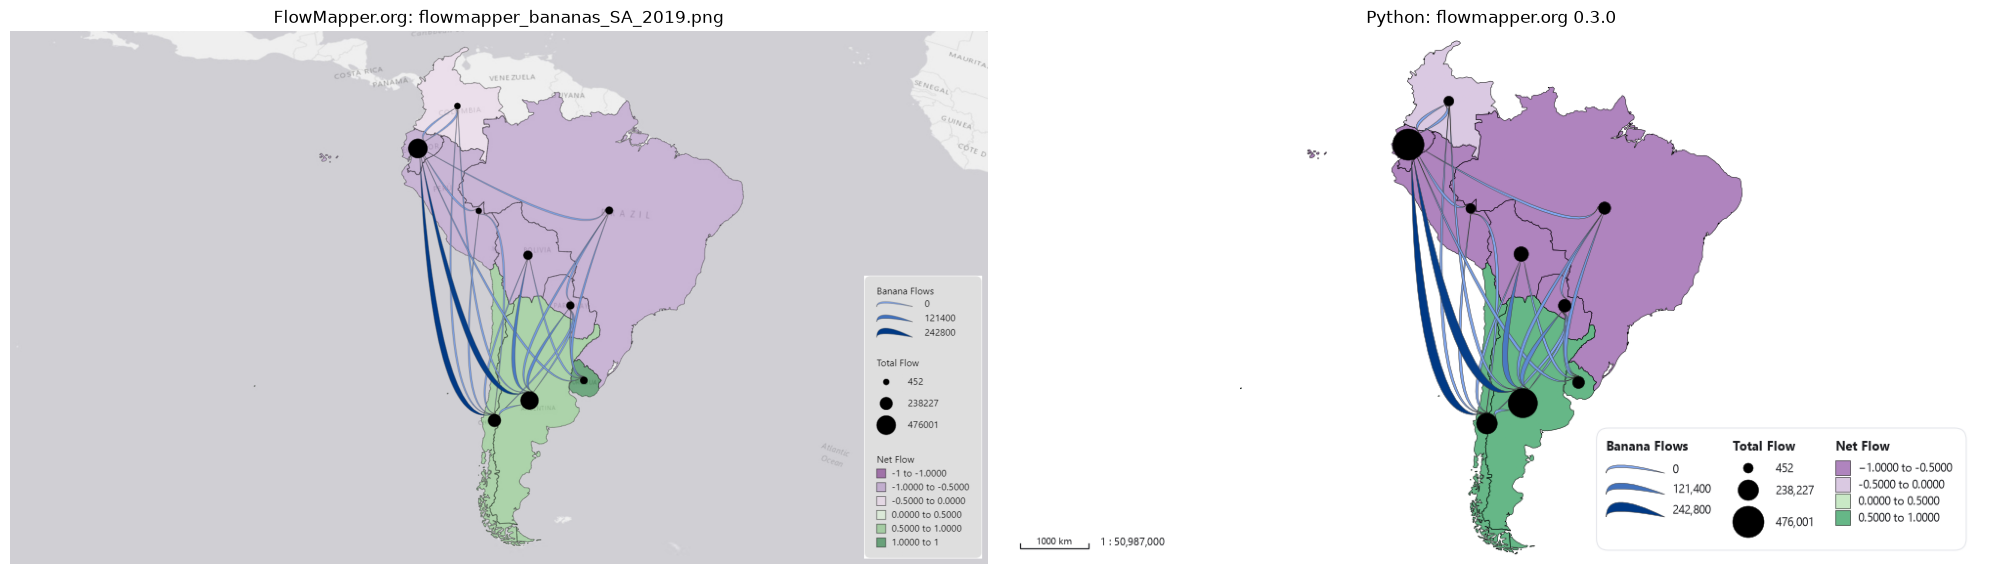

==================== flowmapper_bikeshare_chicago_042021


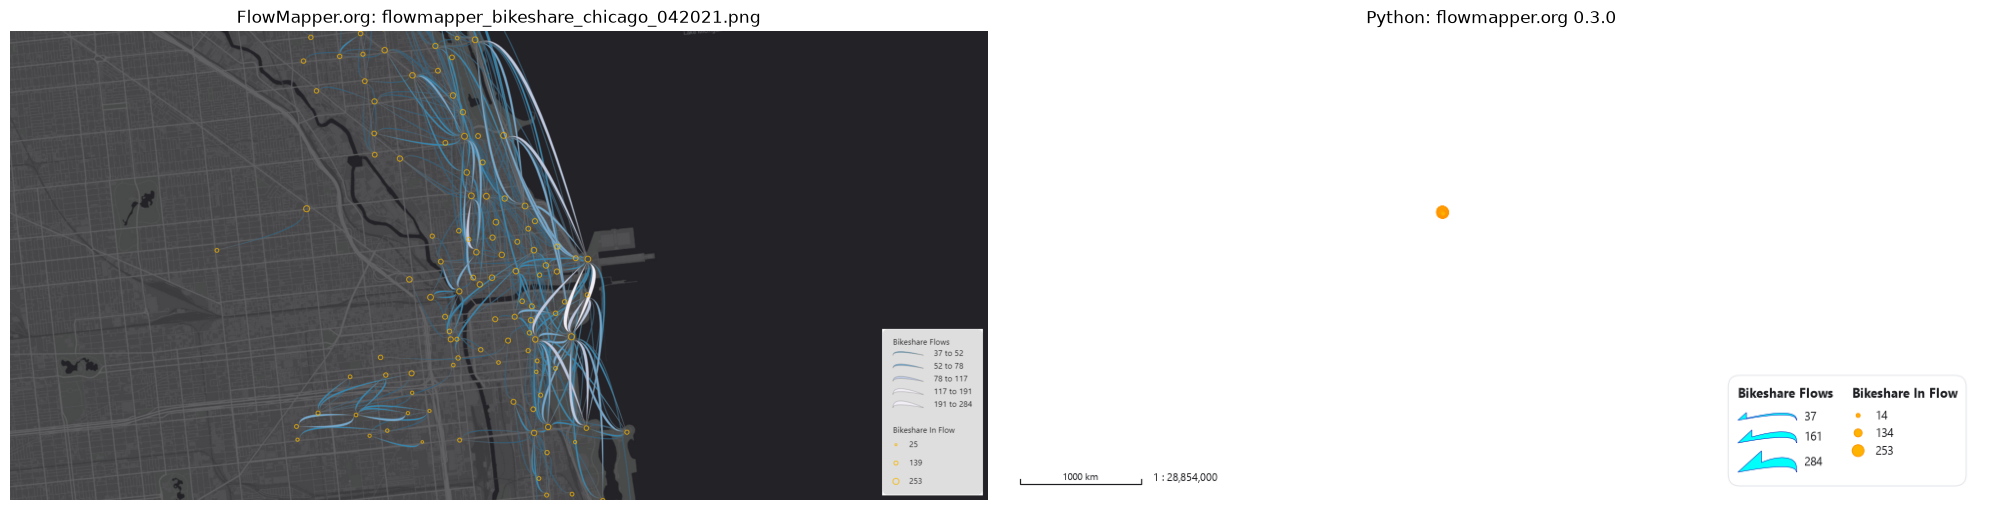

==================== flowmapper_butte_out_2017_18
notice: The flow file has 55 flows between two different nodes, so "Show top flows" was set to 55.


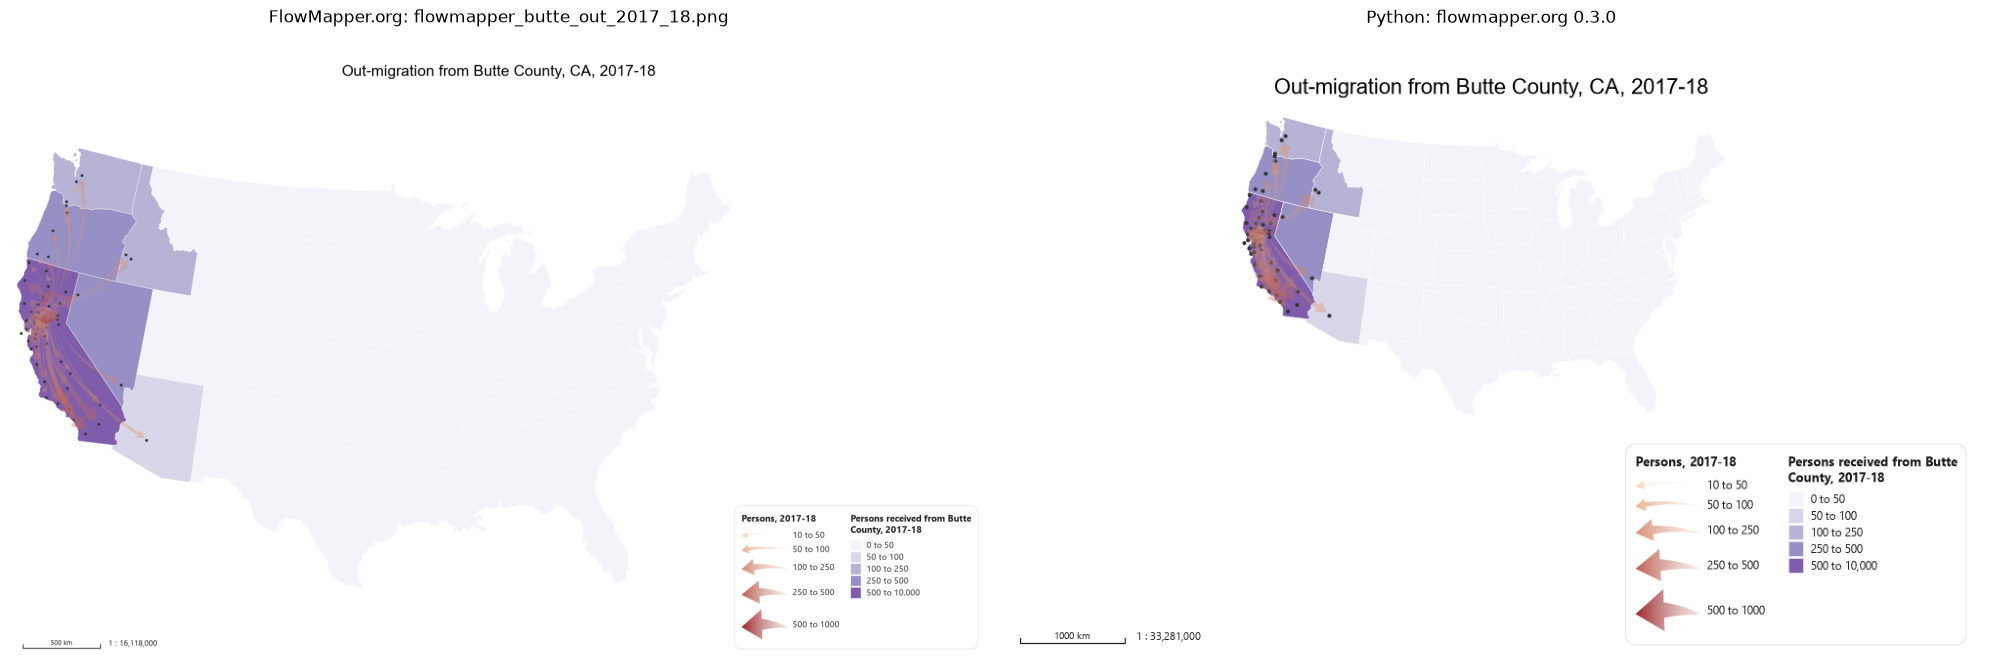

==================== flowmapper_butte_out_2018_19
notice: The flow file has 72 flows between two different nodes, so "Show top flows" was set to 72.


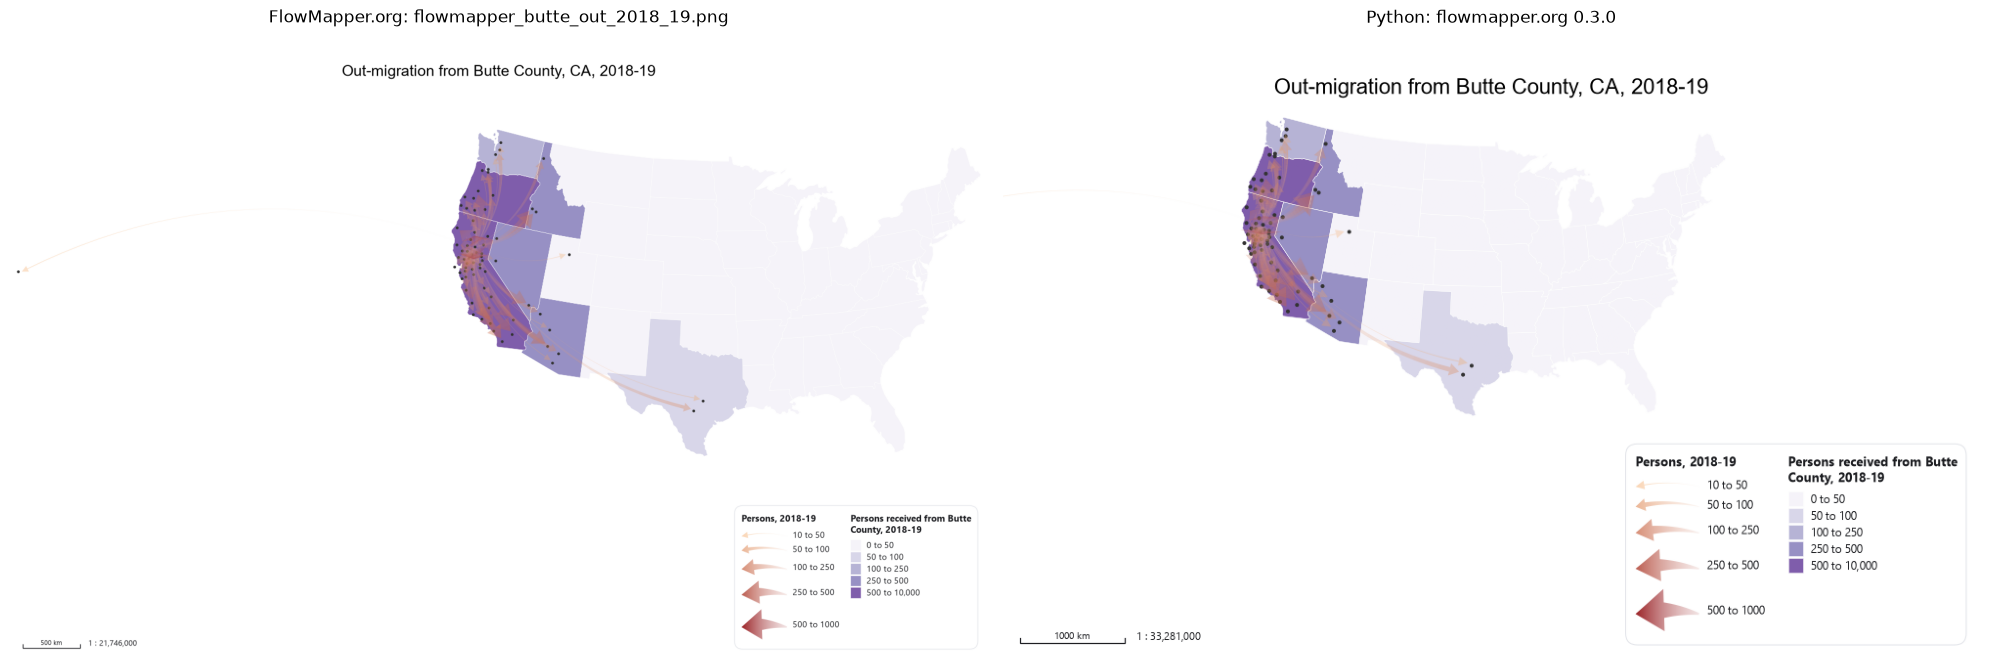

==================== flowmapper_katrina_out_2004_05


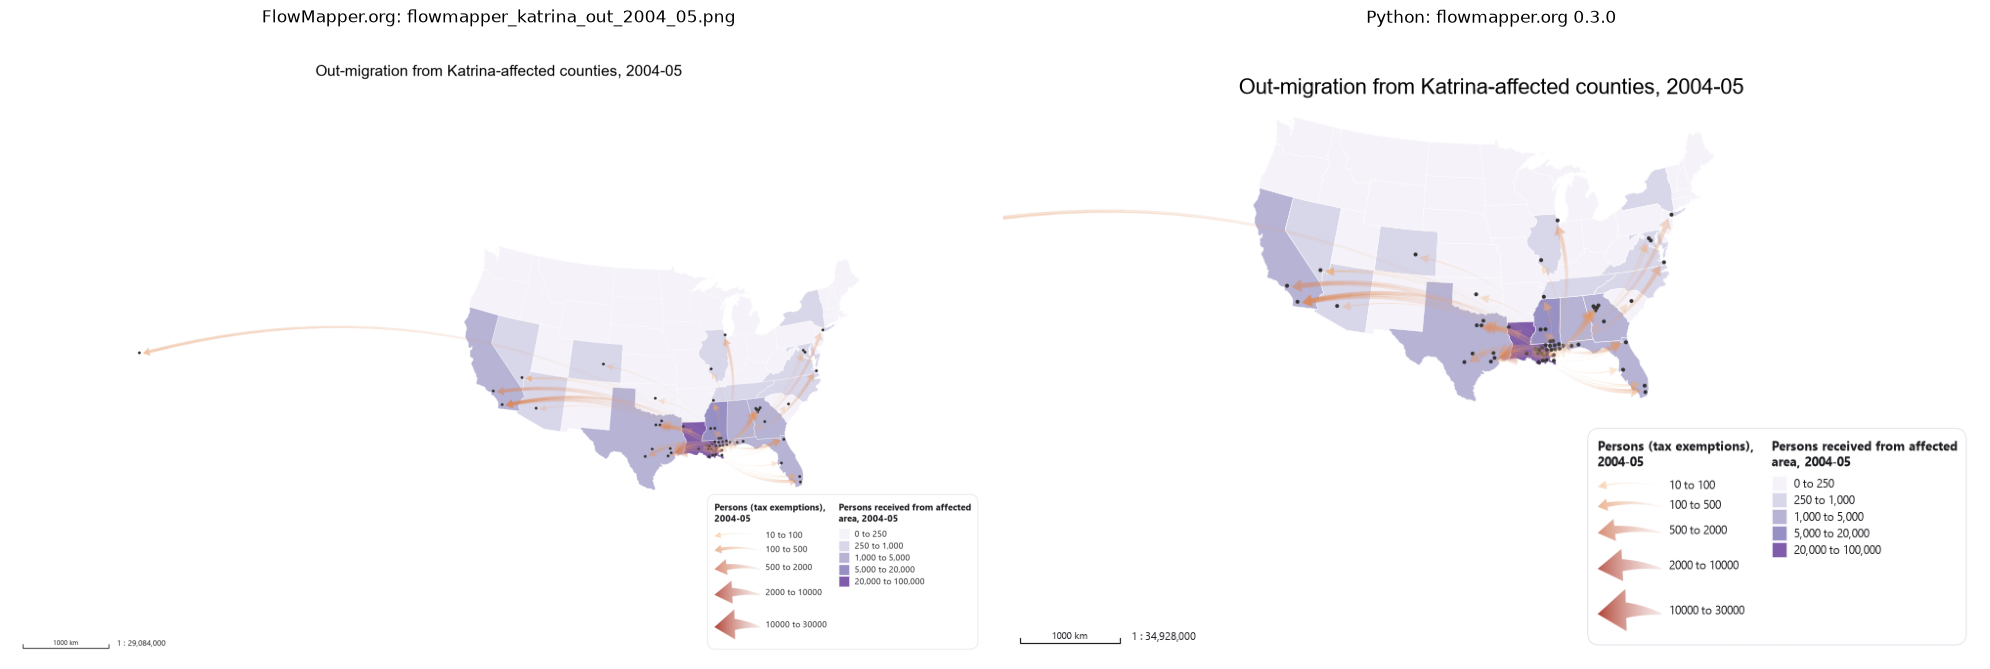

==================== flowmapper_katrina_out_2005_06


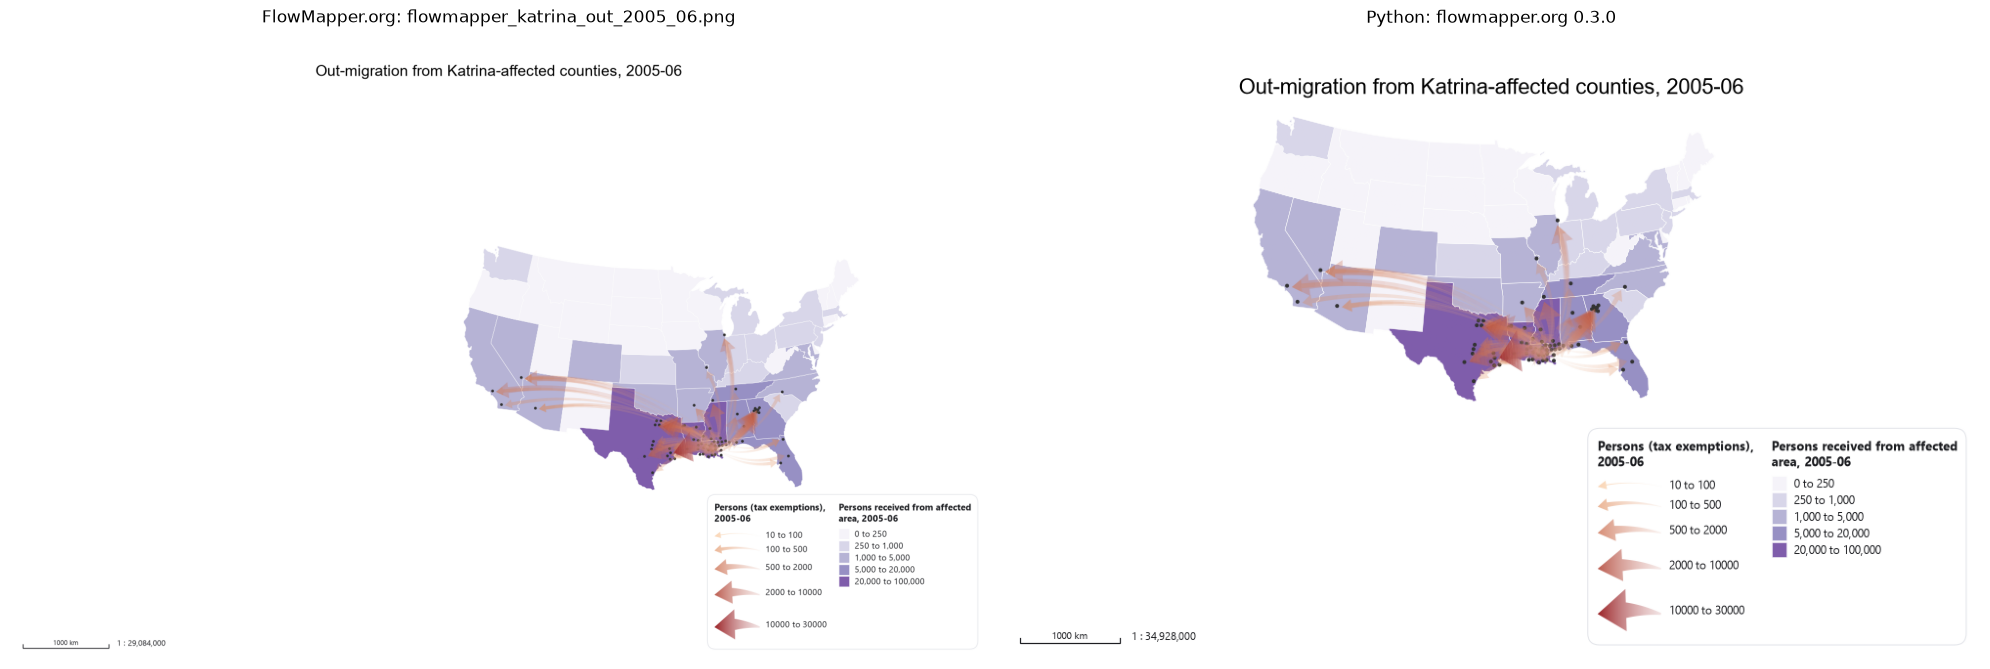

==================== flowmapper_1887_1924
notice: 154 flows use node IDs that are not in the node file (or have no coordinates), e.g. 143, 102, 108, 115, 149, .... They are not drawn.


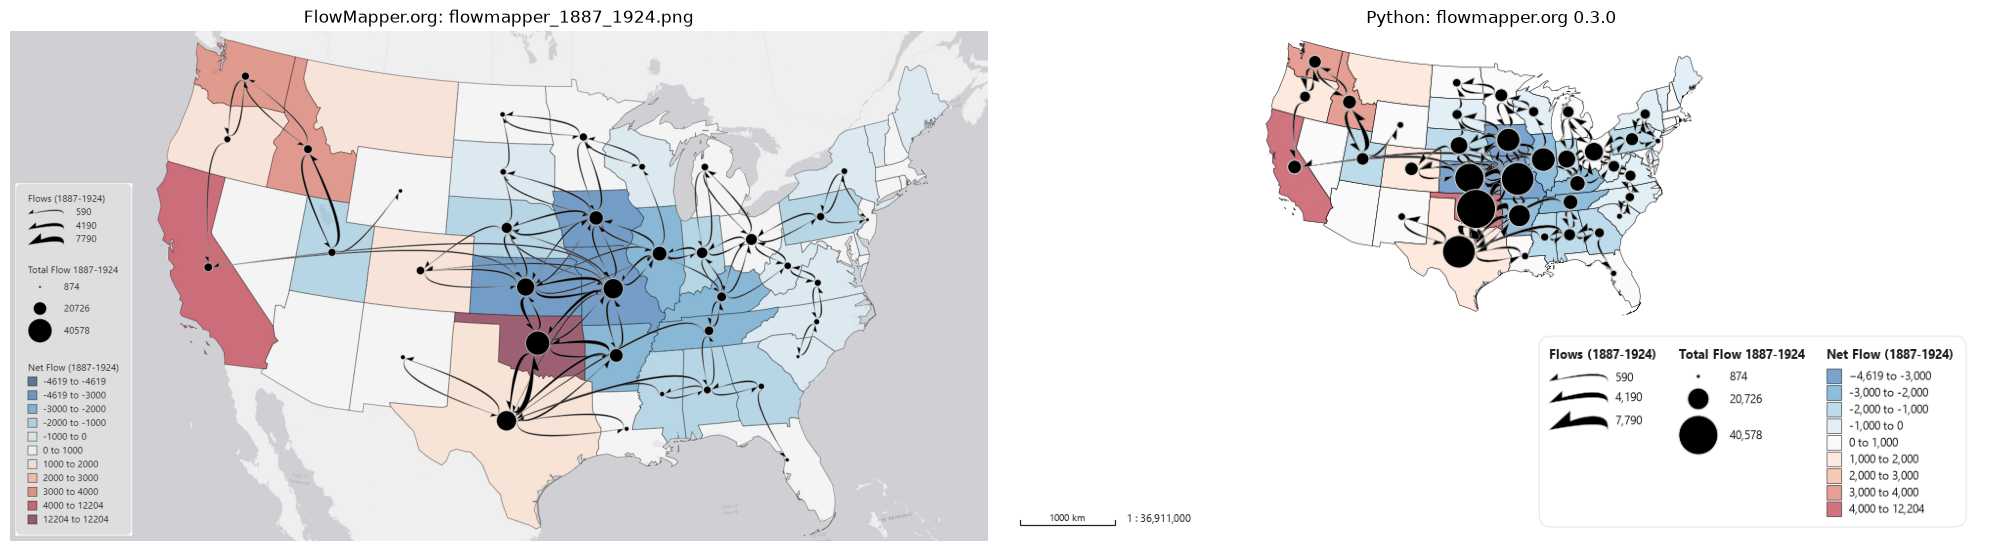

==================== flowmapper_syria_refugees_2015


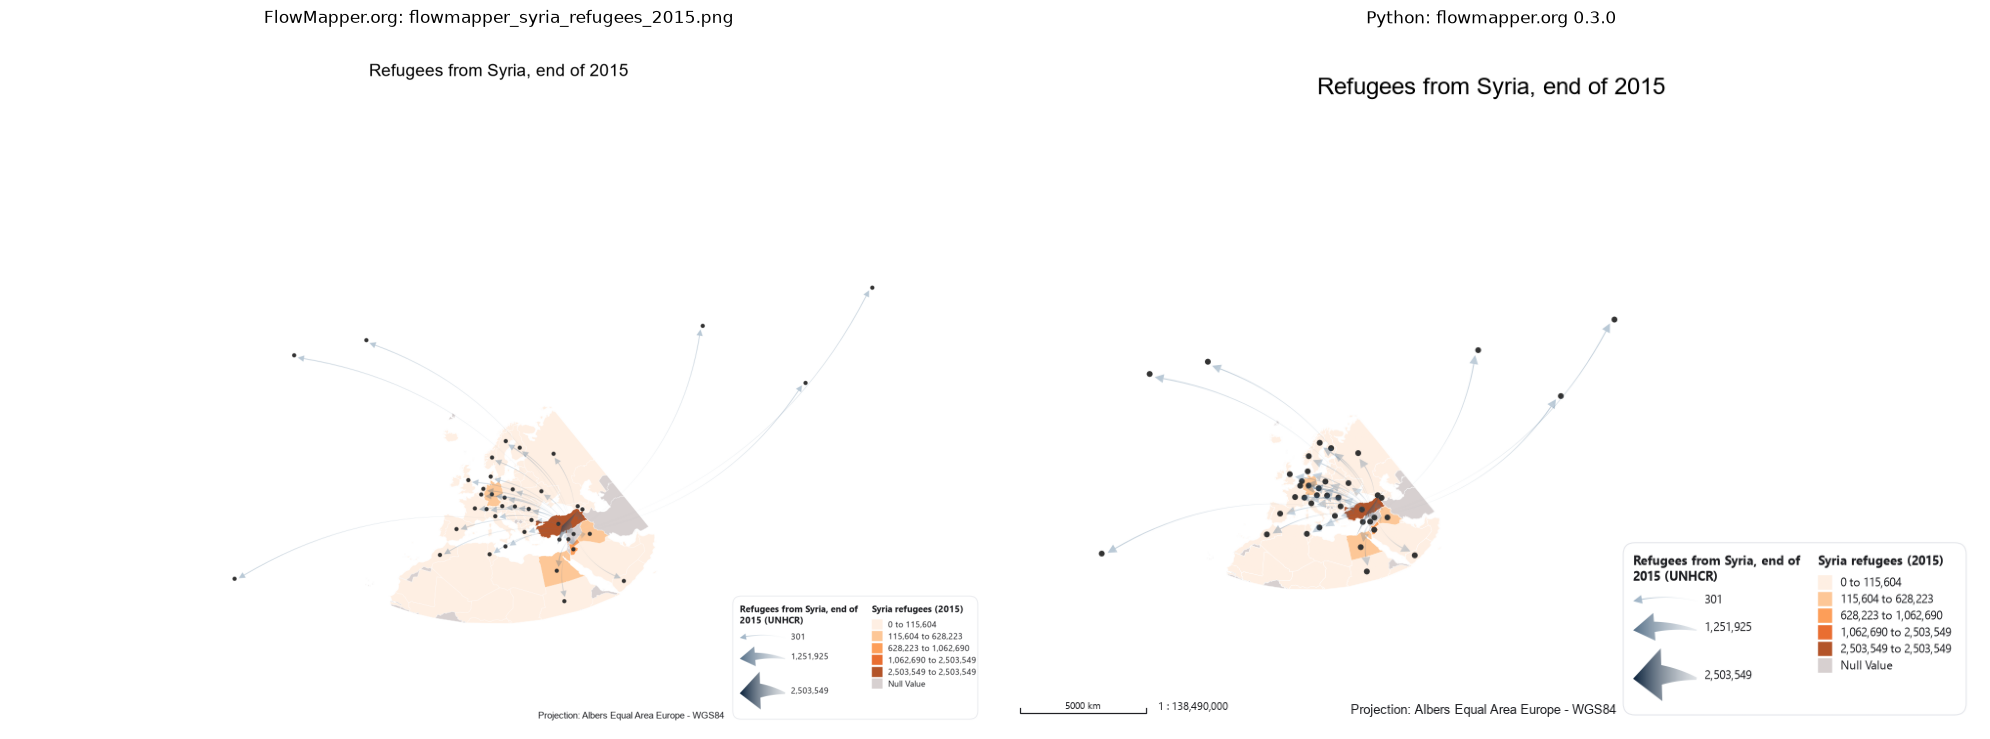

==================== flowmapper_syria_refugees_2024


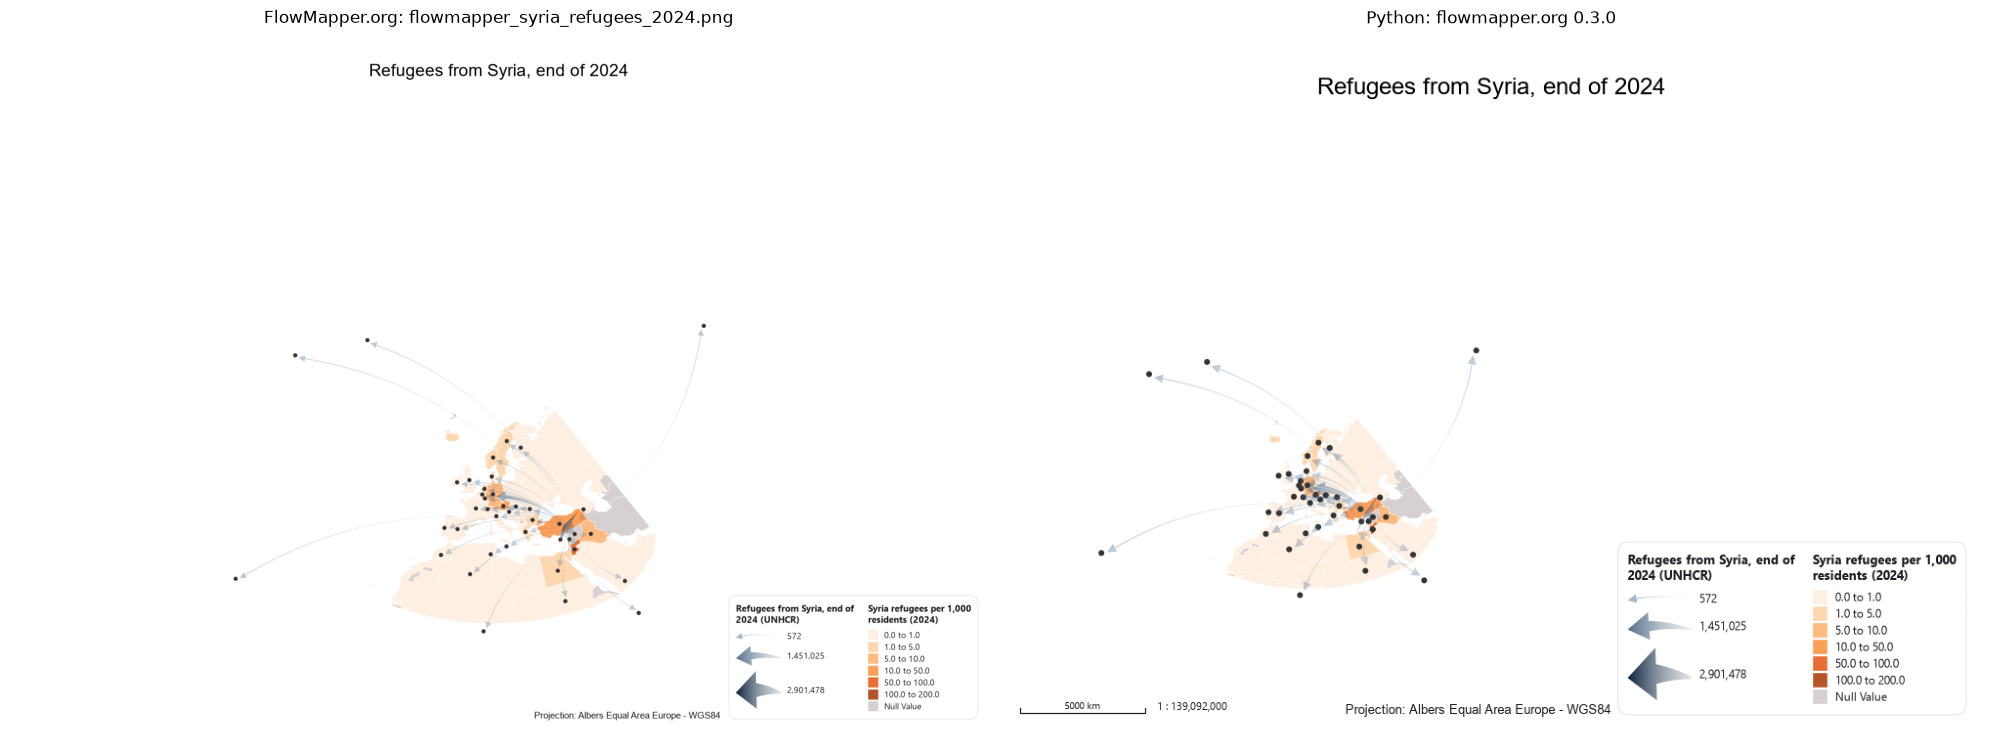

==================== flowmapper_ukraine_refugees_2022


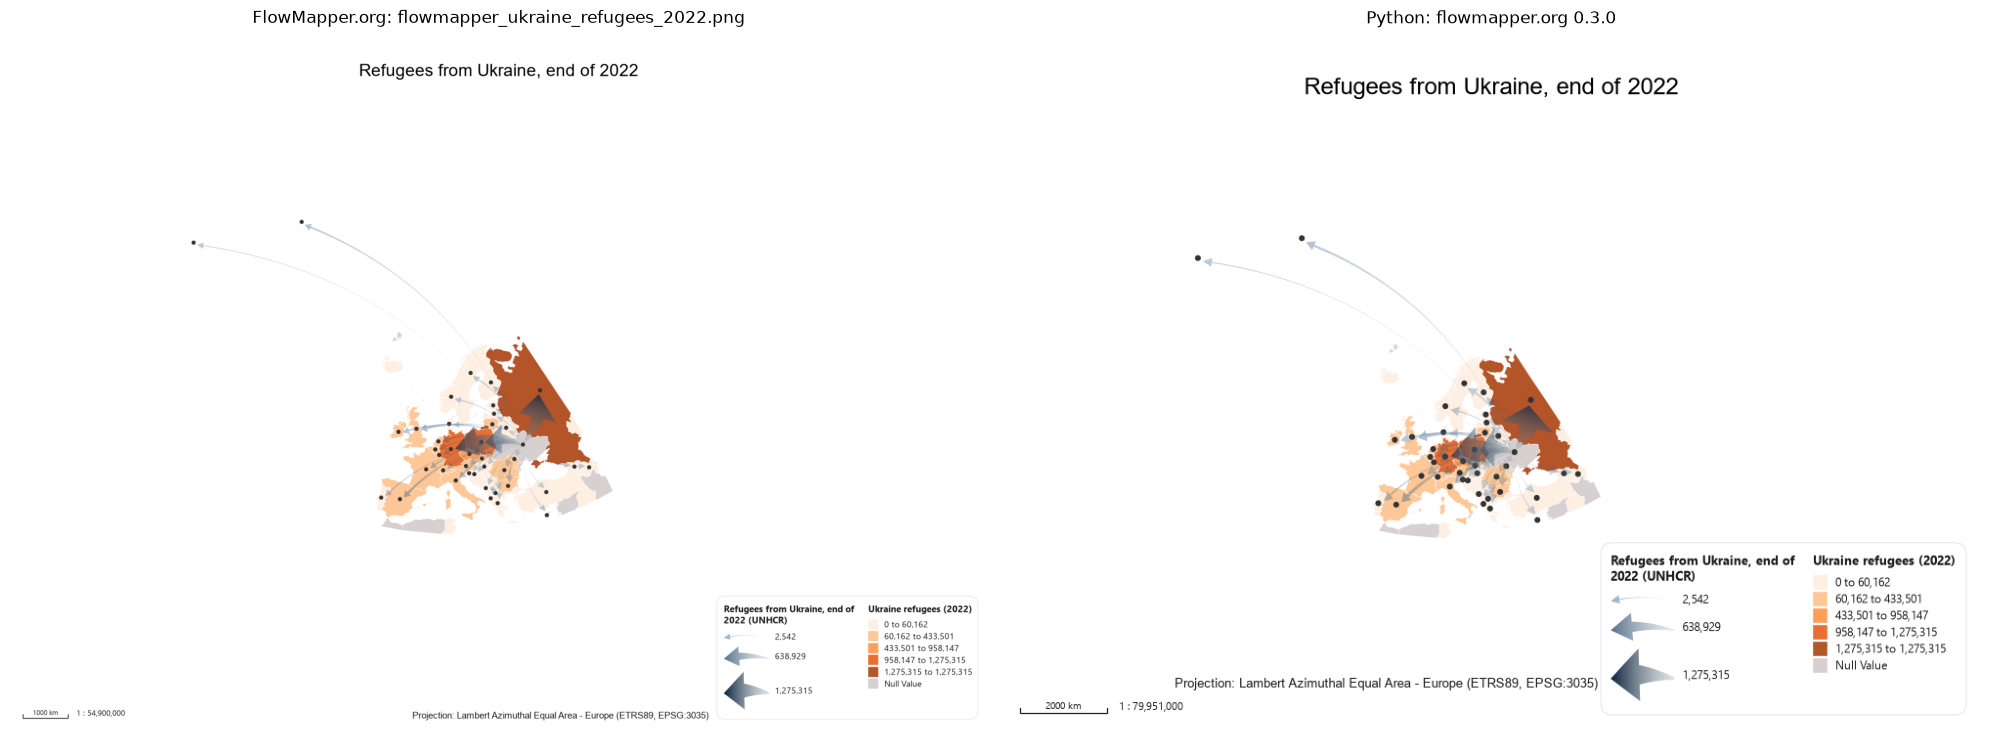

==================== flowmapper_ukraine_refugees_2024


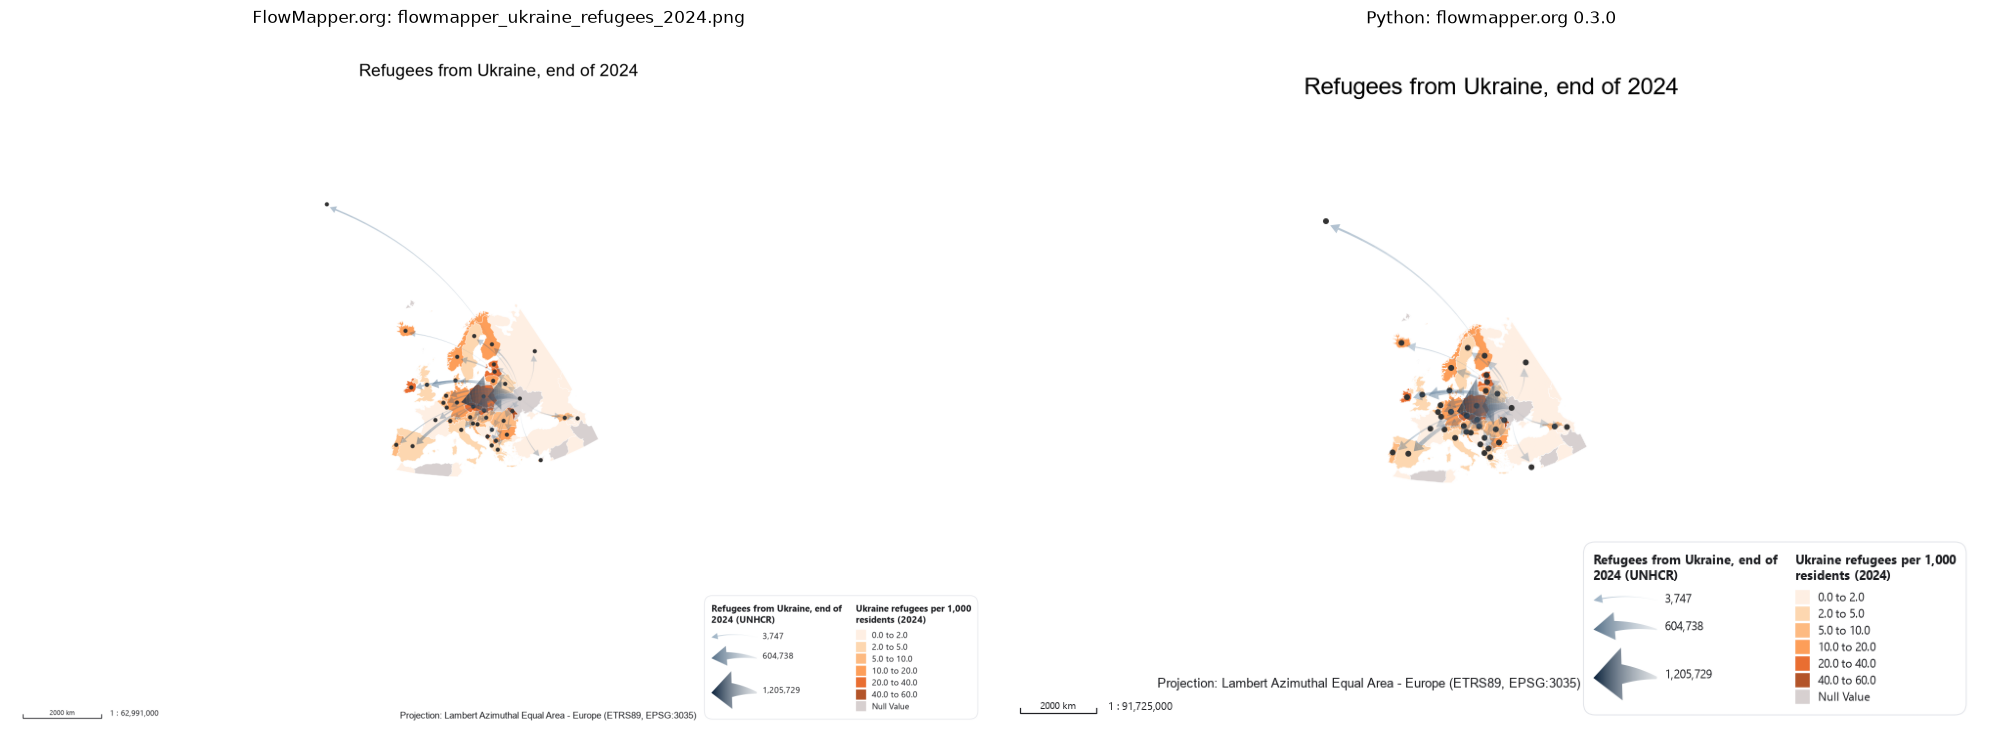

In [3]:
def compare(stem):
    f, p = projects[stem]
    web = plt.imread(f.with_suffix(".png"))
    h, w = web.shape[:2]
    scale = 1000 / w                       # draw the Python map with the picture's aspect ratio
    py = map_image(p, contrast=False, width=w * scale, height=h * scale)
    show_grid([web, py], ["FlowMapper.org: " + f.with_suffix(".png").name, "Python: flowmapper.org " + fm.__version__],
              ncols=2, width=20)

for stem in projects:
    print("=" * 20, stem)
    compare(stem)

## Round trip: Python → project file → Python

In [4]:
import json

for stem, (f, p) in projects.items():
    out = OUT / f"{stem}_roundtrip.json"
    p.save(out)
    q = fm.Project.load(out)
    same = json.dumps(p.to_dict(), sort_keys=True) == json.dumps(q.to_dict(), sort_keys=True)
    print(f"{stem:45s} identical after reload: {same}")

flowmapper_bananas_SA_2019                    identical after reload: True


flowmapper_bikeshare_chicago_042021           identical after reload: True
flowmapper_butte_out_2017_18                  identical after reload: True
flowmapper_butte_out_2018_19                  identical after reload: True
flowmapper_katrina_out_2004_05                identical after reload: True
flowmapper_katrina_out_2005_06                identical after reload: True


flowmapper_1887_1924                          identical after reload: True
flowmapper_syria_refugees_2015                identical after reload: True
flowmapper_syria_refugees_2024                identical after reload: True
flowmapper_ukraine_refugees_2022              identical after reload: True


flowmapper_ukraine_refugees_2024              identical after reload: True


## Restyle a saved project

The Katrina project as saved (left) and with `figure_ground()`: its region colours drawn pale,
dark-red flows at full opacity, nodes sized by total flow and drawn on top (right). Only settings
change, so the restyled project opens on FlowMapper.org too.

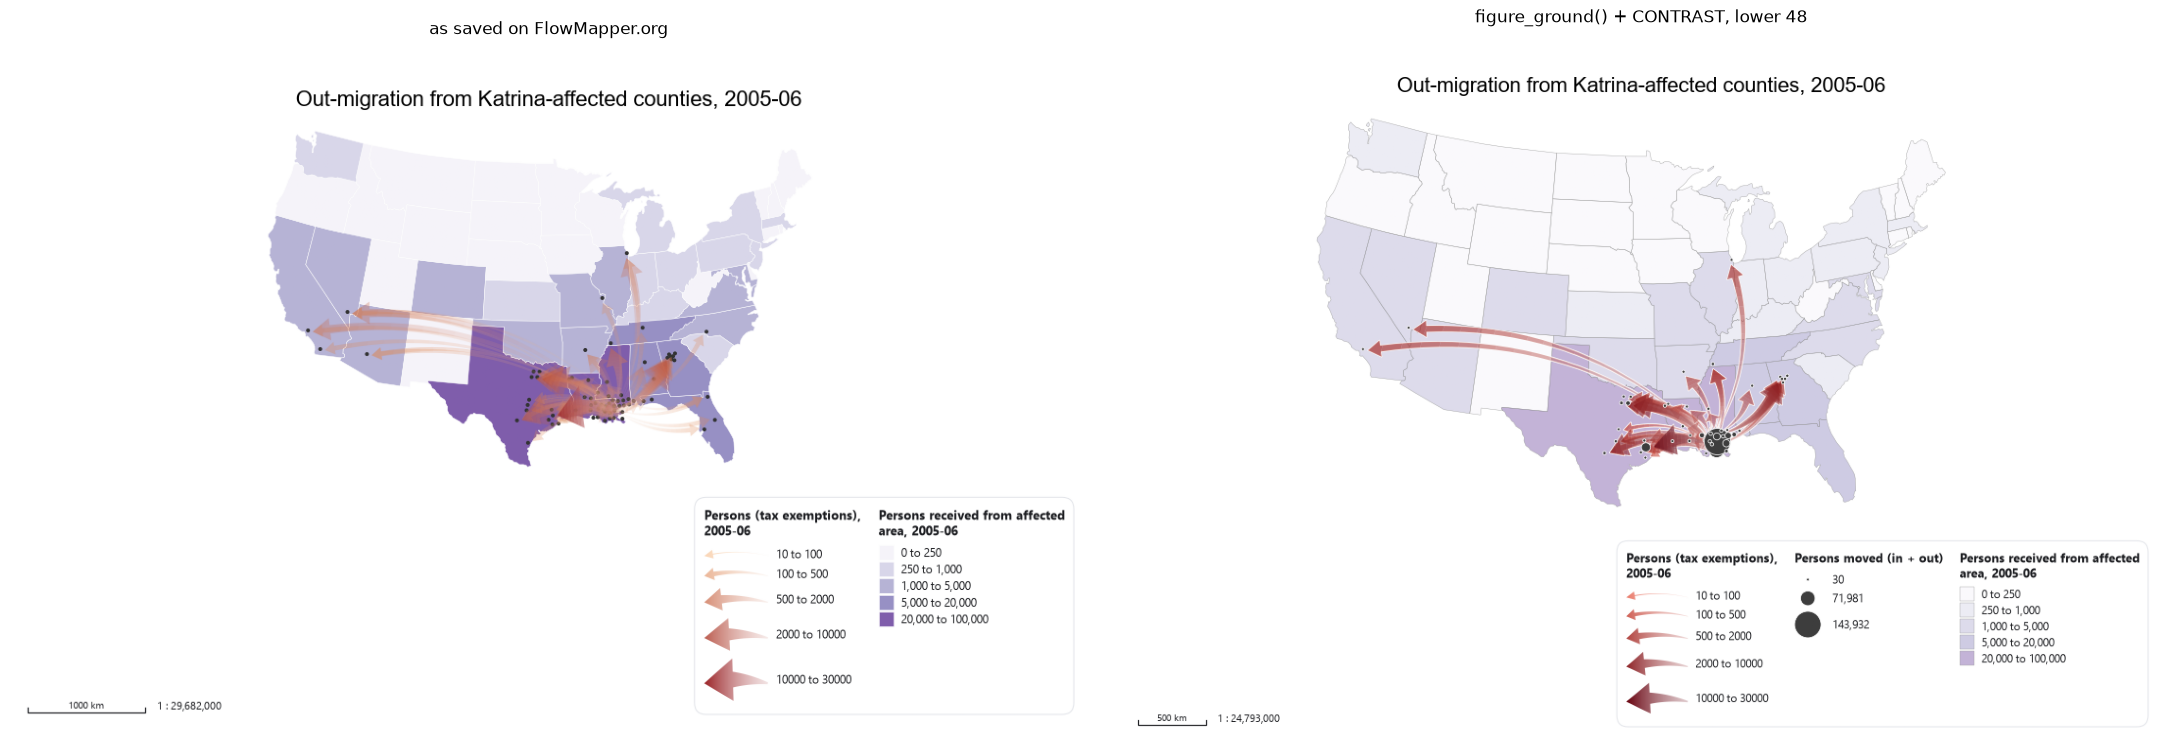

WindowsPath('output/katrina_2005_06_contrast.json')

In [5]:
f, p = projects["flowmapper_katrina_out_2005_06"]
q = p.copy()
figure_ground(q, flows=("#e34a33", "#67000d"))
q.flow_settings.update(numTopFlows=80, widthMax=12)
size_nodes_by_total_flow(q, rmin=1.5, rmax=14, title="Persons moved (in + out)")
show_grid([map_image(p, contrast=False, width=1100, height=700), map_image(q, width=1100, height=750, extent=LOWER48)],
          ["as saved on FlowMapper.org", "figure_ground() + CONTRAST, lower 48"], ncols=2, width=22)
q.save(OUT / "katrina_2005_06_contrast.json")